## Step 1: Import libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Step 2: Set paths and load the datasets

In [2]:
PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Class names:", class_names)

Found 1506 files belonging to 3 classes.
Found 323 files belonging to 3 classes.
Found 323 files belonging to 3 classes.
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


## Step 3: Normalize the datasets

In [3]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

## Step 4: Calculate class weights

we have 1,000 images each for early and late blight, but only 152 healthy images. Class weights help the model give more importance to the underrepresented healthy class during training.

In [4]:
from sklearn.utils.class_weight import compute_class_weight

# Collect training labels
train_labels = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

# Calculate balanced class weights
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=train_labels
)

class_weights = dict(enumerate(class_weights_array))

print("Class weights:")
for index, weight in class_weights.items():
    print(f"{class_names[index]}: {weight:.3f}")

Class weights:
Potato___Early_blight: 0.717
Potato___Late_blight: 0.717
Potato___healthy: 4.736


## Step 5: Build the CNN architecture
 we'll create our first CNN model from scratch. It will have:
- Convolutional layers: Learn visual features such as spots, edges, and leaf patterns.
- Max pooling: Reduce image dimensions while retaining important features.
- Dropout: Help reduce overfitting.
- Dense layers: Use the learned features to classify the leaf into one of three classes.

In [5]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

Summary tells us:
- 3 convolutional layers extract image features.
- 3 max-pooling layers reduce spatial dimensions.
- Global average pooling reduces the extracted feature maps.
- Dropout (0.3) helps reduce overfitting.
- Output layer (3 neurons) predicts one of our three potato leaf classes.
- 101,699 trainable parameters will be learned during training.
The model is relatively lightweight, which is helpful given your computer's available resources.

## Step 6: Compile the model

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## Step 7: Set up training callbacks
Before training, let's configure:
- EarlyStopping: Stops training if validation loss stops improving.
- ModelCheckpoint: Saves the best model based on validation loss.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

Path("../models").mkdir(parents=True, exist_ok=True)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath="../models/cnn_baseline.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, model_checkpoint]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


## Step 8: Train the CNN

In [8]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

c:\Users\Admin\Documents\Potato_Leaf_Disease_Project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step - accuracy: 0.4117 - loss: 1.0962
Epoch 1: val_loss improved from None to 0.99258, saving model to ../models/cnn_baseline.keras

Epoch 1: finished saving model to ../models/cnn_baseline.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 40s 385ms/step - accuracy: 0.4117 - loss: 1.0962 - val_accuracy: 0.5015 - val_loss: 0.9926
Epoch 2/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.4456 - loss: 0.9854
Epoch 2: val_loss improved from 0.99258 to 0.87318, saving model to ../models/cnn_baseline.keras

Epoch 2: finished saving model to ../models/cnn_baseline.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 36s 380ms/step - accuracy: 0.4456 - loss: 0.9854 - val_accuracy: 0.5015 - val_loss: 0.8732
Epoch 3/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.5876 - loss: 0.7204
Epoch 3: val_loss improved from 0.87318 to 0.84123, saving model to ../models/cnn_baseline.keras

Epoch 3: finished saving model to ../models/cnn_baseline.keras
95/95 ━━━━━━━━━━━━━━━━━━━━

The best validation loss was 0.4132, at Epoch 4. Your ModelCheckpoint saved that version, and EarlyStopping restored its weights.

What this tells us
There is evidence of overfitting and unstable validation performance. We should investigate the model's predictions rather than assume that high training accuracy means good classification.

## Plot training history

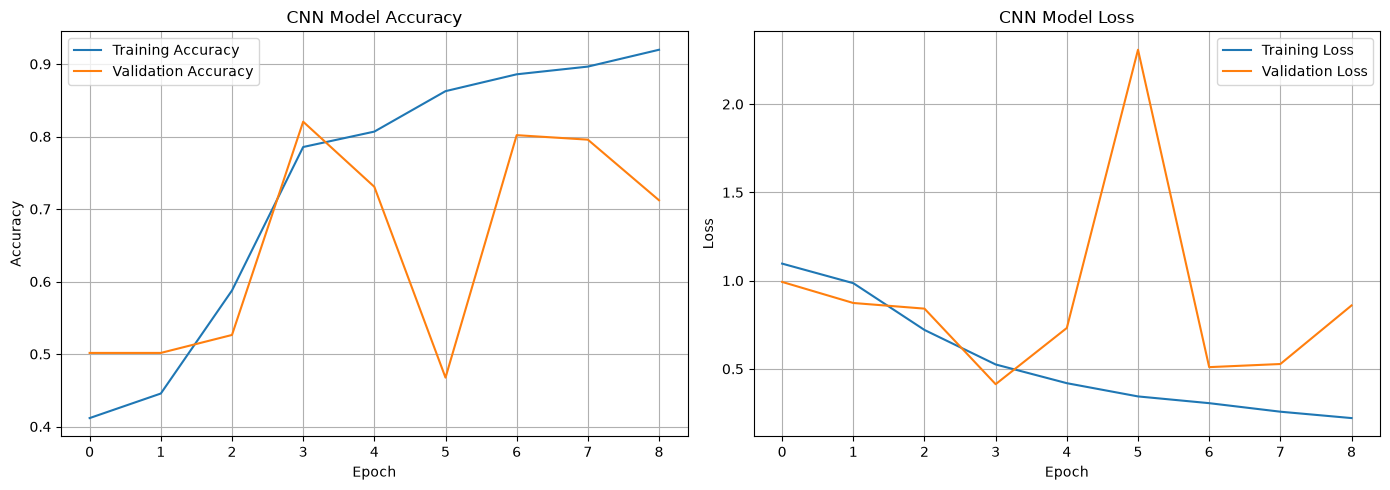

In [9]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## . Interpretion
Accuracy graph
- Training accuracy steadily increases from 41% to 92%.
- Validation accuracy reaches its highest point at Epoch 4 (82.04%).
- After Epoch 4, validation accuracy fluctuates considerably.
Loss graph
- Training loss steadily decreases, which is a good sign.
- Validation loss reaches its lowest point at Epoch 4 (0.4132).
- The large spike at Epoch 6 suggests the model struggled to generalize consistently to unseen images.
This indicates possible overfitting. We should investigate further using the test dataset.

## Step 9: Evaluate the CNN on test data
Remember, the test dataset contains 323 images that the model has not used for training or validation.

In [10]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.8235 - loss: 0.3685
Test Loss: 0.3685
Test Accuracy: 0.8235
Test Accuracy (%): 82.35%


Baseline CNN achieved 82.35% test accuracy, meaning it correctly classified approximately 266 of the 323 test images.

## Step 10: Generate a classification report
We'll calculate:
- Precision: How often a predicted class is correct.
- Recall: How many actual images of a class the model identifies correctly.
- F1-score: A balance between precision and recall.

In [11]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

# Collect actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step
                       precision    recall  f1-score   support

Potato___Early_blight     0.7590    0.9867    0.8580       150
 Potato___Late_blight     0.9706    0.6600    0.7857       150
     Potato___healthy     0.7308    0.8261    0.7755        23

             accuracy                         0.8235       323
            macro avg     0.8201    0.8243    0.8064       323
         weighted avg     0.8552    0.8235    0.8185       323



What these results tell us:
- Early blight: The model identifies almost all actual early blight images, but some images from other classes are incorrectly classified as early blight.
- Late blight: The model is very precise when predicting late blight, but misses about 34% of actual late blight images.
- Healthy: The model identifies approximately 83% of healthy leaves. However, this result is based on only 23 test images, so interpret it cautiously.
Our main concern is the relatively low recall for late blight.

## Step 11: Generate a confusion matrix
A confusion matrix will show exactly which classes the model confuses with one another.

<Figure size 800x600 with 0 Axes>

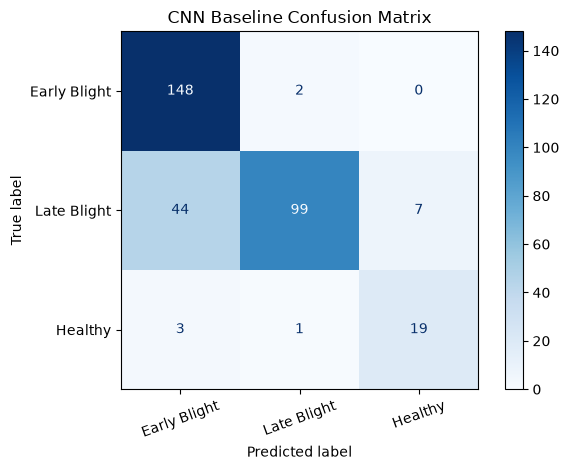

In [12]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Early Blight",
        "Late Blight",
        "Healthy"
    ]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("CNN Baseline Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Understanding the confusion matrix

148 of 150
 Early blight images were correctly classified.

99 of 150
 Late blight images were correctly classified.

19 of 23
 Healthy images were correctly classified.

The most important finding is:

44 late blight images were incorrectly classified as early blight.

This explains why:
- Early blight has very high recall (98.67%).
- Late blight has lower recall (66%).

The model tends to confuse late blight with early blight.